# Predicting major metro service interruptions

This notebook builds and evaluates the prediction framework. It uses the cleaned data from
[`clean_data.py`](clean_data.py); see the [README](README.md) for a description and implications of cleaning decisions.

The brief was to develop a predictive framework for major interruptions. This notebook tries two framings, each focused on train incidents only:

1. **Part 1: predict at the moment an incident is reported** whether it will cause a delay of
   10 minutes or more. This is the most obvious interpretation. While we do find signal, it is not 
   easy to act on.
2. **Part 2: predict once the delay has already lasted 5 minutes** whether it will reach
   30 minutes or more. Elapsed time is information the control room has in real time, and this
   framing leaves more time to act. On the success criterion defined below it does much better
   (34% of major delays caught, against 14%), but it still falls short.

We then additionally use the planned-kilometres data to check whether the trend in interruptions reflects
service volume, and check whether incidents are classified consistently over time.

For the conclusions, recommendations and complete writeup, see README.md

Sections:

1. Setup: data, time split, features, evaluation tools
2. Part 1: at report time, 10+ minutes
3. Part 2: already at 5 minutes, 30+ minutes
4. Robustness checks: excluded features, features whose timing is assumed, target definition
5. Reliability trends: service volume and classification

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from sklearn.calibration import calibration_curve
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score

from clean_data import clean_incidents, clean_planned_km

# Chart colours (a colour-blind-safe pair) and a quiet chart style.
BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#898781"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 1,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "text.color": "#0b0b0b",
    "font.size": 11,
})

## 1. Setup

### 1.1 Data: train incidents only

Station incidents do not affect metro service (the documentation says so explicitly), for maximum impact and ease of interpretation we focus only on train incidents and exclude station incidents. Every model below uses **train incidents only**.

In [2]:
incidents = clean_incidents()
trains = incidents[incidents["incident_type"] == "T"].copy()

first_day = trains["service_date"].min().date()
last_day = trains["service_date"].max().date()
print(f"{len(trains):,} train incidents, from {first_day} to {last_day}")

  Removed 5 duplicate rows
29,166 train incidents, from 2019-01-01 to 2025-09-30


### 1.2 Construct Splits by time

| Period | Years | Use |
|---|---|---|
| Training | 2019 to 2023 | Fit and define models |
| Validation | 2023, with models fit on 2019 to 2022 | Compare the two models (sections 2.3 and 3.4) |
| Test | 2024 to September 2025 | Evaluate the methods. Nothing is fitted on these years |

A random split would let the model learn from incidents that happen *after* the ones it is
tested on. Splitting by time mimics how the model would be used: trained on the past, applied to
the future. Everything that shapes a model or a rule (including the risk tables in Part 2) is
computed on the training years only. 2023 appears in two rows: it is held back while the two
models are compared, then included when the final models are fit.

Caveats: the training years include the COVID period (2020 to 2021), when service and ridership
changed. The documentation warns that incidents can appear more than 30 days after a month closes,
but the latest months look complete: the file is dated July 2026, nine months after its last
incident, and the check below finds no more gaps in the daily incident numbers than in the same
months of earlier years, and a similar rate of missing causes.


In [3]:
# The final models: fit on the training years, evaluated on the test years.
trains["period"] = np.where(trains["year"] <= 2023, "train", "test")
display(trains["period"].value_counts())

# Comparing the two models: fit on 2019 to 2022, scored on the validation year.
trains["validation_split"] = "test years"
trains.loc[trains["year"] <= 2023, "validation_split"] = "validation"
trains.loc[trains["year"] <= 2022, "validation_split"] = "fit"
trains["validation_split"].value_counts()

period
train    21057
test      8109
Name: count, dtype: int64

validation_split
fit           16560
test years     8109
validation     4497
Name: count, dtype: int64

In [4]:
# Are the latest months complete? Incident numbers run in sequence within each day (T01082509 is
# number 09 on 01-08-25), so missing incidents would leave gaps. April to September of each year:
same_months = trains[(trains["year"] >= 2023) & trains["month"].between(4, 9)].copy()
same_months["daily_number"] = same_months["incident_id"].str[7:].astype(int)
highest_each_day = same_months.groupby(["year", "service_date"])["daily_number"].max()

completeness = pd.DataFrame({
    "incidents": same_months.groupby("year").size(),
    "days with an incident": highest_each_day.groupby("year").size(),
    "daily numbers present": same_months.groupby("year").size() / highest_each_day.groupby("year").sum(),
    "no cause recorded": same_months["primary_cause"].isna().groupby(same_months["year"]).mean(),
})
completeness.round(3)

,incidents,days with an incident,daily numbers present,no cause recorded
year,,,,
2023,2070,183,0.964,0.022
2024,2520,183,0.974,0.015
2025,1670,182,0.978,0.022


### 1.3 Features: our assumptions on what is known when a live prediction is made

| Column | Used? | Why |
|---|---|---|
| `symptom` | Yes | The initial cause, assigned *at the moment of the incident* (per the documentation) |
| `affected_station` | Yes | Where the incident is |
| `line`, `location_type` | Yes | Where the incident is. Whether it affects *several* lines may only be recorded once a delay spreads; section 4.2 checks this |
| `start_service_hour` | Yes | Time of day. The service-day hour keeps late-night service together (00:10 is hour 24, not 0) |
| `weekday`, `month` | Yes | Calendar effects |
| `emergency_brake`, `door_involved` | Yes | Describe how the incident started. Assumed known at report time (not documented); section 4.2 checks this |
| `has_vehicle`, `has_run` | Yes | Whether a train car or run number is recorded. Assumed known at report time; section 4.2 checks this |
| `primary_cause`, `secondary_cause`, `rolling_stock_at_fault` | **No** | Decided after analysis, sometimes weeks later |
| `metro_emergency` | **No** | Calling the emergency team *is* an escalation: it is part of the response, not a predictor |
| `traction_power_cut`, `evacuation`, `material_damage` | **No** (section 4.1 only) | When they are set is not documented; they may be consequences of a long incident |
| `duration_bucket`, `duration_minutes`, `end_datetime` | **No** | They are the outcome |

Missing values are made explicit categories: an unknown symptom becomes `Inconnu`, and incidents
not at a station get the station value `(pas une station)`.

In [5]:
trains["symptom"] = trains["symptom"].fillna("Inconnu")
trains["line"] = trains["line"].fillna("Inconnue")
trains["station"] = trains["affected_station"].fillna("(pas une station)")
trains["has_vehicle"] = trains["vehicle"].notna().astype(int)
trains["has_run"] = trains["run_number"].notna().astype(int)

CATEGORICAL_FEATURES = ["symptom", "line", "station", "location_type",
                        "start_service_hour", "weekday", "month"]
BINARY_FEATURES = ["emergency_brake", "door_involved", "has_vehicle", "has_run"]


def make_feature_matrix(data, extra_binary_features=(), dropped_features=()):
    """One column per category value (one-hot), plus the 0/1 features.

    extra_binary_features and dropped_features are only used for the robustness checks
    in section 4.
    """
    categorical = []
    for column in CATEGORICAL_FEATURES:
        if column not in dropped_features:
            categorical.append(column)
    binary = []
    for column in BINARY_FEATURES + list(extra_binary_features):
        if column not in dropped_features:
            binary.append(column)

    features = data[categorical + binary].copy()
    for column in categorical:
        features[column] = features[column].astype(str)
    return pd.get_dummies(features, columns=categorical, dtype=float)

### 1.4 What counts as a major interruption

STM's indicators ignore interruptions of under 5 minutes, but it does not define a "major" one, so
that definition is our choice. Training years only:

In [6]:
train_years = trains[trains["period"] == "train"]

by_duration = (train_years.groupby(["bucket_min_minutes", "duration_bucket"])
               .size().reset_index(name="incidents"))
by_duration["share of incidents"] = (by_duration["incidents"] / len(train_years)).round(3)
by_duration.drop(columns="bucket_min_minutes")

,duration_bucket,incidents,share of incidents
0,02 min et moins,11844,0.562
1,03 à 04 min,4657,0.221
2,05 à 09 min,3145,0.149
3,10 à 14 min,651,0.031
4,15 à 19 min,206,0.010
5,20 à 24 min,108,0.005
6,25 à 29 min,78,0.004
7,30 min et plus,368,0.017


In [7]:
# Interruptions by length: how much delay do they cause, and how serious are they?
delays_5_plus = train_years[train_years["bucket_min_minutes"] >= 5].copy()
delays_5_plus["length"] = pd.cut(delays_5_plus["bucket_min_minutes"], bins=[5, 10, 15, 30, np.inf],
                                 right=False,
                                 labels=["5 to 9 min", "10 to 14 min", "15 to 29 min", "30+ min"])
delays_5_plus["evacuated"] = (delays_5_plus["evacuation"] != "Aucune").astype(int)

severity = delays_5_plus.groupby("length", observed=True).agg(
    interruptions=("duration_minutes", "size"),
    delay_minutes=("duration_minutes", "sum"),
    median_minutes=("duration_minutes", "median"),
    emergency_team=("metro_emergency", "mean"),
    evacuation=("evacuated", "mean"),
    material_damage=("material_damage", "mean"),
)
severity.insert(1, "share of interruptions", severity["interruptions"] / severity["interruptions"].sum())
severity.insert(3, "share of delay minutes", severity["delay_minutes"] / severity["delay_minutes"].sum())

severity.round(3)

,interruptions,share of interruptions,delay_minutes,share of delay minutes,median_minutes,emergency_team,evacuation,material_damage
length,,,,,,,,
5 to 9 min,3145,0.690,21336,0.344,6.0,0.010,0.071,0.002
10 to 14 min,651,0.143,8603,0.139,11.0,0.060,0.226,0.009
15 to 29 min,392,0.086,8133,0.131,19.0,0.143,0.426,0.018
30+ min,368,0.081,24029,0.387,52.0,0.427,0.777,0.220


- **10+ minutes (Part 1):** past the 5 to 9 minutes that make up 69% of interruptions, so no longer
  a routine delay.
- **30+ minutes (Part 2):** 8% of interruptions but 39% of the delay minutes, with an evacuation in
  78% of them (23% at 10 to 14 minutes).

In [8]:
part1_rate = (train_years["bucket_min_minutes"] >= 10).mean()
part2_rate = (delays_5_plus["bucket_min_minutes"] >= 30).mean()
print(f"Part 1, 10+ minutes among all train incidents: {part1_rate:.1%}")
print(f"Part 2, 30+ minutes among delays that reached 5 minutes: {part2_rate:.1%}")

Part 1, 10+ minutes among all train incidents: 6.7%
Part 2, 30+ minutes among delays that reached 5 minutes: 8.1%


### 1.5 Evaluation tools

Major interruptions are rare (under 10% of incidents, as shown above), so accuracy is meaningless: predicting
"never major" would be over 90% accurate. We use:

- **PR-AUC** (average precision): how well the model identifies major incidents.
- **ROC-AUC**, for reference (0.5 = random).
- **Our defined success-criterion** (for greater explanation see section 2.1): the largest share of major incidents caught
  while at least 1 alert in 3 is right, and how many alerts that takes.
- **An alert table**: if the control room escalated the riskiest X% of incidents (riskiest meaning the
  highest predicted probability of being major), how many major ones would it catch (recall), and what share of alerts would be right (precision)?
- **A bootstrap interval** for the difference in PR-AUC between two methods, to check whether a
  difference is larger than chance.

Every model is compared with two baselines: the **base rate** (no information) and a **symptom
rule**: a lookup table, built from the training years, that gives every incident the share of
past incidents with the same symptom that became major (for example 55% for fire or smoke in
Part 2). It is what a controller could do with no model at all.

**Models.** Logistic regression is the main model, because it is simple and interpretable.
Gradient boosting, a more flexible model, is shown as a check that it would not do much better.
Neither is tuned. Sections 2.3 and 3.4 compare them on the validation year.

In [9]:
def gradient_boosting():
    """The gradient boosting model, with the same settings everywhere.

    Early stopping is off. Otherwise scikit-learn turns it on above 10,000 rows (so in Part 1 only)
    and holds back a random 10% of the training rows to decide when to stop.
    """
    return HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4,
                                          early_stopping=False, random_state=0)


def symptom_rule_scores(train_data, test_data, target_column):
    """Score each test incident with its symptom's rate of major delays in the training years."""
    rate_by_symptom = train_data.groupby("symptom")[target_column].mean()
    overall_rate = train_data[target_column].mean()
    return test_data["symptom"].map(rate_by_symptom).fillna(overall_rate).to_numpy()


def model_scores(model, data, target_column, extra_binary_features=(), dropped_features=()):
    """Fit the model on the training years and return its scores for the test years."""
    features = make_feature_matrix(data, extra_binary_features, dropped_features)
    is_train = data["period"] == "train"
    model.fit(features[is_train], data.loc[is_train, target_column])
    return model.predict_proba(features[~is_train])[:, 1]


def validation_pr_auc(model, data, target_column):
    """Fit on 2019 to 2022, and return the PR-AUC on the validation year, 2023."""
    features = make_feature_matrix(data)
    fit_rows = data["validation_split"] == "fit"
    validation_rows = data["validation_split"] == "validation"
    model.fit(features[fit_rows], data.loc[fit_rows, target_column])
    scores = model.predict_proba(features[validation_rows])[:, 1]
    return average_precision_score(data.loc[validation_rows, target_column], scores)


def compare_on_validation_year(data, target_column):
    """PR-AUC of the two models on the validation year, with its base rate and major incidents."""
    in_validation = data["validation_split"] == "validation"
    return pd.DataFrame([{
        "base rate (2023)": round(data.loc[in_validation, target_column].mean(), 3),
        "major incidents (2023)": int(data.loc[in_validation, target_column].sum()),
        "logistic regression": round(validation_pr_auc(
            LogisticRegression(max_iter=2000), data, target_column), 3),
        "gradient boosting": round(validation_pr_auc(gradient_boosting(), data, target_column), 3),
    }])


def recall_with_precision_floor(y_test, scores, min_precision=1 / 3):
    """The success-criterion measure (section 2.1).

    The largest share of major incidents caught (recall) at any alert threshold where at least
    `min_precision` of the alerts are right, and how many alerts that threshold gives.
    Returns (0, 0) if no threshold is that precise.
    """
    scores = np.asarray(scores)
    precision, recall, thresholds = precision_recall_curve(y_test, scores)
    # The curve's final point (recall 0) has no threshold, so it is dropped.
    precise_enough = precision[:-1] >= min_precision
    if not precise_enough.any():
        return 0.0, 0
    best_recall = recall[:-1][precise_enough].max()
    # Among the thresholds that catch this share, the highest gives the fewest alerts.
    best_threshold = thresholds[precise_enough & (recall[:-1] == best_recall)].max()
    return best_recall, int((scores >= best_threshold).sum())


def compare_methods(y_test, scores_by_method):
    """PR-AUC, ROC-AUC and the success-criterion measure for each method."""
    rows = []
    for method, scores in scores_by_method.items():
        pr_auc = average_precision_score(y_test, scores)
        recall, alerts = recall_with_precision_floor(y_test, scores)
        rows.append({
            "method": method,
            "PR-AUC": round(pr_auc, 3),
            "PR-AUC / base rate": round(pr_auc / y_test.mean(), 1),
            "ROC-AUC": round(roc_auc_score(y_test, scores), 3),
            "recall, 1 in 3 alerts right": round(recall, 2),
            "alerts needed": alerts,
        })
    return pd.DataFrame(rows)


def alert_table(y_test, scores, alert_rates):
    """If we escalate the riskiest X% of incidents, how many major ones do we catch?

    Incidents with equal scores are taken in file order (sorted by incident number), which is
    effectively arbitrary. This only matters for the symptom rule, which gives many equal scores.
    """
    y_test = np.asarray(y_test)
    riskiest_first = np.argsort(-np.asarray(scores), kind="stable")
    rows = []
    for rate in alert_rates:
        n_alerts = int(round(rate * len(y_test)))
        caught = y_test[riskiest_first[:n_alerts]].sum()
        rows.append({
            "escalate the riskiest": f"{rate:.0%}",
            "alerts": n_alerts,
            "major caught": int(caught),
            "of major": int(y_test.sum()),
            "recall": round(caught / y_test.sum(), 2),
            "precision": round(caught / n_alerts, 2),
        })
    return pd.DataFrame(rows)


def bootstrap_pr_auc_difference(y_test, scores_a, scores_b, n_resamples=1000, seed=0):
    """95% interval for PR-AUC(a) - PR-AUC(b), resampling the test incidents with replacement.

    The same resampled incidents are used for both methods, so the interval reflects the
    difference between them. The fitted models are held fixed.
    """
    rng = np.random.default_rng(seed)
    y_test = np.asarray(y_test)
    scores_a = np.asarray(scores_a)
    scores_b = np.asarray(scores_b)
    differences = []
    for _ in range(n_resamples):
        sample = rng.integers(0, len(y_test), len(y_test))
        difference = (average_precision_score(y_test[sample], scores_a[sample])
                      - average_precision_score(y_test[sample], scores_b[sample]))
        differences.append(difference)
    low, high = np.percentile(differences, [2.5, 97.5])
    return round(low, 3), round(high, 3)

## 2. Part 1: at report time, will the delay reach 10 minutes?

**Question.** When a train incident is reported, will it cause a delay of 10 minutes or more?

- **Population:** all train incidents, including those that caused no delay (at report time,
  nobody knows yet whether there will be one).
- **Target:** `duration_bucket` of `10 à 14 min` or longer. We use STM's own duration category and not the start and end times, we explain this in section 2.2 and verify in section 4.3.
- **Why 10 minutes:** STM's indicators ignore interruptions under 5 minutes, and 5 to 9 minutes is
  the most common real delay. 10 minutes and more is the tail where escalation could matter
  (section 1.4).

### 2.1 Success criterion

For the model to support escalation, **there should be an alert threshold at which at least half
of the major incidents are caught, while at least 1 alert in 3 is right.** Precision/recall tradeoff. Below that, the control
room would either miss most major interruptions or learn to ignore the alerts. This bar is an
operational assumption to discuss with STM for the purpose of this exercise - this criterion would obviously be discussed with them in a real-life consulting scenario. The same bar is
applied to Part 2.

The results tables show this as *recall, 1 in 3 alerts right* is the largest share of major
incidents caught at any threshold where at least 1 alert in 3 is right, and *alerts needed* is how
many alerts that threshold gives on the test years.


### 2.2 Target and base rate

The next cell does three things:

1. **Creates the target, `major`:** 1 if the incident's duration category is `10 à 14 min` or
   longer, 0 otherwise. `bucket_min_minutes` is the lower limit of each category (for example
   10 for `10 à 14 min`), so `>= 10` keeps every category from `10 à 14 min` up.
2. **Checks the target against the start and end times.** The target uses STM's duration
   category, not our own calculation from the times, because it is STM's published
   classification, which we read as the delay to service, and it does not depend on how we converted
   the service-day times. This is a judgment call: the category is not documented, and the
   documentation defines the start and end times as the delay to customers. The two measures do not always agree: the times give 18% more major
   incidents, and almost never fewer. As a bonus, Section 4.3 shows what these incidents are, and that the
   conclusions do not change when the target is defined by the times.
3. **Shows the base rate in each period**, the share of incidents that are major. Every result
   below has to be read against it: a random ranking has a PR-AUC about equal to the base rate. It also
   shows whether the two periods are comparable. The test years have a slightly higher rate than
   the training years, in line with a gradual rise since 2019 (5.4% that year). A model trained on
   the earlier years may therefore give slightly low probabilities. Most of the metrics
   only depend on how incidents are ranked, so they should be much less affected, unless the rise
   is concentrated in certain kinds of incident.

In [10]:
part1 = trains.copy()
part1["major"] = (part1["bucket_min_minutes"] >= 10).astype(int)

major_by_times = part1["duration_minutes"] >= 10
print(f"10+ minutes by the duration category: {part1['major'].sum():,}; "
      f"by the start and end times: {major_by_times.sum():,}")
print(f"Major by the times only: {(major_by_times & (part1['major'] == 0)).sum()}; "
      f"by the category only: {(~major_by_times & (part1['major'] == 1)).sum()}")

part1.groupby("period")["major"].agg(incidents="count", major="sum", major_rate="mean").round(3)

10+ minutes by the duration category: 2,036; by the start and end times: 2,407
Major by the times only: 375; by the category only: 4


,incidents,major,major_rate
period,,,
test,8109,625,0.077
train,21057,1411,0.067


### 2.3 Results

**Comparing the models.** Logistic regression and gradient boosting are fit on 2019 to 2022 and
compared on the validation year, 2023:

In [11]:
compare_on_validation_year(part1, "major")

,base rate (2023),major incidents (2023),logistic regression,gradient boosting
0,0.077,345,0.188,0.187


The two are very close so we make the decision to keep both for now, despite the role of the validation set. Neither model is tuned; tuning on this validation year, for example the strength of the logistic regression's regularisation, could improve the results slightly and is what one could do with more time. 


**Test years.** The models are refit on 2019 to 2023 and evaluated on 2024 to September 2025:

In [12]:
part1_train = part1[part1["period"] == "train"]
part1_test = part1[part1["period"] == "test"]
y1 = part1_test["major"]

part1_scores = {
    "base rate (no information)": np.full(len(y1), part1_train["major"].mean()),
    "symptom rule": symptom_rule_scores(part1_train, part1_test, "major"),
    "logistic regression": model_scores(LogisticRegression(max_iter=2000), part1, "major"),
    "gradient boosting": model_scores(gradient_boosting(), part1, "major"),
}
compare_methods(y1, part1_scores)

,method,PR-AUC,PR-AUC / base rate,ROC-AUC,"recall, 1 in 3 alerts right",alerts needed
0,base rate (no information),0.077,1.0,0.500,0.00,0
1,symptom rule,0.118,1.5,0.612,0.00,0
2,logistic regression,0.262,3.4,0.766,0.14,244
3,gradient boosting,0.277,3.6,0.766,0.20,374


In [13]:
print("Logistic regression:")
display(alert_table(y1, part1_scores["logistic regression"], alert_rates=[0.05, 0.10, 0.20]))

low, high = bootstrap_pr_auc_difference(y1, part1_scores["logistic regression"], part1_scores["symptom rule"])
print(f"PR-AUC, logistic regression minus symptom rule: 95% interval {low} to {high}")

Logistic regression:


,escalate the riskiest,alerts,major caught,of major,recall,precision
0,5%,405,112,625,0.18,0.28
1,10%,811,179,625,0.29,0.22
2,20%,1622,302,625,0.48,0.19


PR-AUC, logistic regression minus symptom rule: 95% interval 0.124 to 0.167


### 2.4 Is it actionable?

The data also records one type of escalation: calling in the metro emergency team
(`metro_emergency`). How often did that happen for major incidents?
These figures cover all years, including the test years; they only describe the response and do
not feed any model.

In [14]:
pd.crosstab(part1["metro_emergency"], part1["major"], margins=True,
            rownames=["metro emergency team called"], colnames=["10+ minute delay"])

10+ minute delay,0,1,All
metro emergency team called,,,
0,27001,1686,28687
1,129,350,479
All,27130,2036,29166


Which incidents get the team? For the most severe delays (30 minutes or more), the share with a
call depends heavily on the symptom:

In [15]:
severe = part1[part1["bucket_min_minutes"] >= 30]
called = severe["metro_emergency"]
print(f"Team called for {called.sum()} of {len(severe)} delays of 30+ minutes ({called.mean():.0%})")

team_by_symptom = (severe.groupby("symptom")["metro_emergency"]
                   .agg(delays_30_min="count", team_called="sum", share_called="mean")
                   .sort_values("delays_30_min", ascending=False))
team_by_symptom["share_called"] = team_by_symptom["share_called"].round(2)
team_by_symptom

Team called for 213 of 524 delays of 30+ minutes (41%)


,delays_30_min,team_called,share_called
symptom,,,
Clientèle,220,129,0.59
"Feu, fumée, odeur, produit, etc...",137,18,0.13
Équipements fixes,105,17,0.16
Matériel roulant,58,49,0.84
Divers,2,0,0.00
Exploitation stations,2,0,0.00


### 2.5 Part 1 conclusion: real signal, but not enough to act on

**The model finds real signal.** Logistic regression scores a PR-AUC of 0.262, 3.4 times the base
rate, and clearly better than the symptom rule (bootstrap interval for the difference: 0.12 to
0.17). Gradient boosting does similarly (0.277).

**But it misses our defined success criterion.** While keeping at least 1 alert in 3
right, it catches only 14% of the 10-minute delays (bar: 50%), with 244 alerts over the 21 test
months (about 12 a month). Catching more means accepting more false alarms: escalating the
riskiest 10% of incidents (811 alerts, about 39 a month) would catch 29%, and only 22% of those
alerts would be right.

**Two weaknesses of this framing, which Part 2 addresses:**

1. **It ignores the strongest real-time signal.** It only uses what is known when the delay
   starts: symptom, place, time and how the incident began. It does not use how long the delay
   has lasted.
2. **It leaves little time to act.** For train incidents, the recorded start time is the start of
   the delay to customers, so the alert fires when customers are already delayed, and the event it
   warns about is short: in the training years, 46% of the 10-minute delays were over before
   15 minutes, often too soon for a response such as replacement buses to make a difference.

**Regardless of what we do consider, we also note that the data cannot show that escalating helps.** There is
no clear record of when or how incidents were escalated and in what manner. 
The one escalation-type response that is recorded, calling the metro emergency team, happened for 479
incidents across all years: 73% of them reached 10 minutes, but they cover only 17% of all 10-minute delays (350 of
2,036) - one could envision a 10 minute delay at least leading to a social media team escalation response.

This does not mean escalation is rare. The team is a *specialised* response: among delays of 30
minutes or more, it was called for 84% of those with a rolling-stock symptom and 59% of those with
a customer symptom, but only 13% of those with fire or smoke and 16% of those with fixed equipment.
Those incidents are presumably handled by other teams, whose involvement is not recorded. So
`metro_emergency` records one type of response, not escalation in general, and the data cannot say
when, or how often, incidents were escalated.

## 3. Part 2: the delay has lasted 5 minutes. Will it reach 30?

### 3.1 Elapsed time changes the picture

The control room knows, in real time, how long a delay has lasted. We investigate how much information this adds.


In [16]:
rows = []
for minutes in [0, 3, 5, 10, 15, 20, 25]:
    still_delayed = part1_train[part1_train["bucket_min_minutes"] >= minutes]
    reaches_30 = (still_delayed["bucket_min_minutes"] >= 30).mean()
    rows.append({
        "delay has lasted at least": f"{minutes} min",
        "incidents": len(still_delayed),
        "share that reach 30+ min": round(reaches_30, 3),
    })
pd.DataFrame(rows)

,delay has lasted at least,incidents,share that reach 30+ min
0,0 min,21057,0.017
1,3 min,9213,0.040
2,5 min,4556,0.081
3,10 min,1411,0.261
4,15 min,760,0.484
5,20 min,554,0.664
6,25 min,446,0.825


### 3.2 The question

**When a train delay has lasted 5 minutes, will it reach 30 minutes or more?**

- **Population:** train incidents whose delay reached 5 minutes. This is exactly STM's own
  definition of an interruption (its indicators ignore anything shorter).
- **Target:** `duration_bucket` of `30 min et plus`, STM's top category. Section 1.4 gives the reason
  for this definition.
- **Decision it supports:** at minute 5, trigger the major-disruption response or not
  (for example public communication, replacement buses or the emergency team; STM's actual
  procedures are not in the data). When the alert is right, at least
  25 minutes of disruption are still to come, enough time for a response to make a difference.
- **Same features** as Part 1, assumed to be known by minute 5 (section 1.3). Section 4.2 shows
  that the Part 2 results do not depend on the features whose timing is uncertain.

In [17]:
part2 = trains[trains["bucket_min_minutes"] >= 5].copy()
part2["major"] = (part2["bucket_min_minutes"] >= 30).astype(int)

part2.groupby("period")["major"].agg(incidents="count", major="sum", major_rate="mean").round(3)

,incidents,major,major_rate
period,,,
test,1857,156,0.084
train,4556,368,0.081


### 3.3 A simple rule: risk by symptom

The symptom is assigned the moment the incident starts. Its rate of 30-minute delays, among delays
that reached 5 minutes, in the training years:

In [18]:
part2_train = part2[part2["period"] == "train"]
symptom_risk = (part2_train.groupby("symptom")["major"]
                .agg(incidents="count", reach_30_min="sum", rate="mean")
                .sort_values("rate", ascending=False))
symptom_risk["rate"] = symptom_risk["rate"].round(3)
symptom_risk

,incidents,reach_30_min,rate
symptom,,,
"Feu, fumée, odeur, produit, etc...",176,97,0.551
Exploitation stations,7,2,0.286
Clientèle,1754,153,0.087
Équipements fixes,928,80,0.086
Divers,32,2,0.062
Matériel roulant,1500,34,0.023
Exploitation trains,150,0,0.000
Inconnu,9,0,0.000


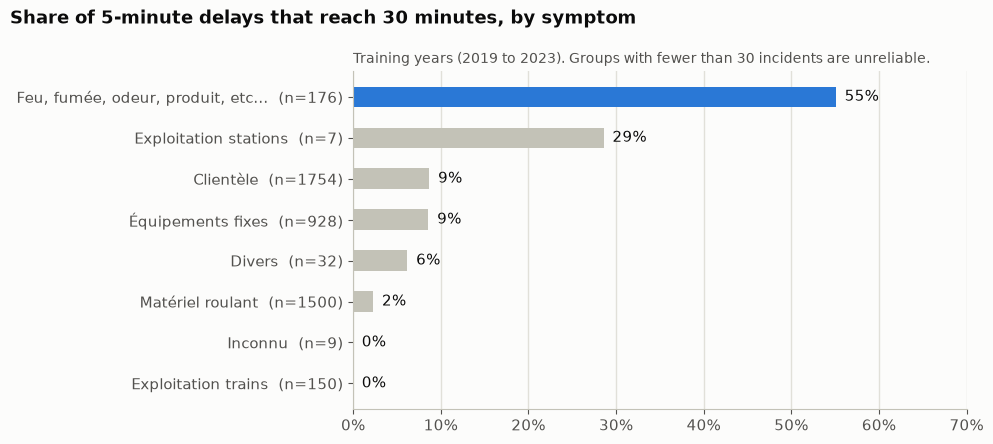

In [19]:
chart_data = symptom_risk.sort_values("rate")
labels = [f"{symptom}  (n={count})" for symptom, count in zip(chart_data.index, chart_data["incidents"])]

# Fire / smoke / odour is the story, so it is the only bar in colour.
colours = []
for symptom in chart_data.index:
    if symptom.startswith("Feu"):
        colours.append(BLUE)
    else:
        colours.append("#c3c2b7")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.set_axisbelow(True)
ax.barh(labels, chart_data["rate"], height=0.5, color=colours)
for position, rate in enumerate(chart_data["rate"]):
    ax.text(rate + 0.01, position, f"{rate:.0%}", va="center", color="#0b0b0b")
ax.set_xlim(0, 0.7)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
fig.suptitle("Share of 5-minute delays that reach 30 minutes, by symptom",
             x=0.01, ha="left", fontweight="bold")
ax.set_title("Training years (2019 to 2023). Groups with fewer than 30 incidents are unreliable.",
             loc="left", fontsize=10, color="#52514e", fontweight="normal")
plt.tight_layout()
plt.show()

### 3.4 Results

**Comparing the models.** The same comparison on the validation year, 2023:

In [20]:
compare_on_validation_year(part2, "major")

,base rate (2023),major incidents (2023),logistic regression,gradient boosting
0,0.065,71,0.258,0.271


Gradient boosting is slightly ahead here, but the gap is small and 2023 has only 71 major incidents.
We again choose to keep both models and display their test results. A more detailed analysis (more time spent) might deal with the low positive cases in 2023 and change decisions accordingly.

**Test years.** The models are refit on 2019 to 2023 and evaluated on 2024 to September 2025:

In [21]:
part2_test = part2[part2["period"] == "test"]
y2 = part2_test["major"]

part2_scores = {
    "base rate (no information)": np.full(len(y2), part2_train["major"].mean()),
    "symptom rule": symptom_rule_scores(part2_train, part2_test, "major"),
    "logistic regression": model_scores(LogisticRegression(max_iter=2000), part2, "major"),
    "gradient boosting": model_scores(gradient_boosting(), part2, "major"),
}
compare_methods(y2, part2_scores)

,method,PR-AUC,PR-AUC / base rate,ROC-AUC,"recall, 1 in 3 alerts right",alerts needed
0,base rate (no information),0.084,1.0,0.500,0.00,0
1,symptom rule,0.213,2.5,0.683,0.26,79
2,logistic regression,0.299,3.6,0.747,0.34,154
3,gradient boosting,0.264,3.1,0.714,0.34,153


In [22]:
print("Symptom rule:")
display(alert_table(y2, part2_scores["symptom rule"], alert_rates=[0.10, 0.20, 0.30]))
print("Logistic regression:")
display(alert_table(y2, part2_scores["logistic regression"], alert_rates=[0.10, 0.20, 0.30]))

low, high = bootstrap_pr_auc_difference(y2, part2_scores["logistic regression"], part2_scores["symptom rule"])
print(f"PR-AUC, logistic regression minus symptom rule: 95% interval {low} to {high}")

Symptom rule:


,escalate the riskiest,alerts,major caught,of major,recall,precision
0,10%,186,48,156,0.31,0.26
1,20%,371,60,156,0.38,0.16
2,30%,557,80,156,0.51,0.14


Logistic regression:


,escalate the riskiest,alerts,major caught,of major,recall,precision
0,10%,186,59,156,0.38,0.32
1,20%,371,74,156,0.47,0.20
2,30%,557,91,156,0.58,0.16


PR-AUC, logistic regression minus symptom rule: 95% interval 0.052 to 0.13


The simplest possible rule: **escalate every fire, smoke or odour incident still delaying service
at minute 5.**

In [23]:
is_fire = part2_test["symptom"].str.startswith("Feu").to_numpy()
alerts = is_fire.sum()
caught = part2_test.loc[is_fire, "major"].sum()
print(f"Alerts: {alerts} ({alerts / len(part2_test):.0%} of 5-minute delays)")
print(f"Major delays caught: {caught} of {y2.sum()} (recall {caught / y2.sum():.2f})")
print(f"Share of alerts that were major: {caught / alerts:.2f}")

# How many of these incidents does the model already put in its riskiest 10%?
n_top = int(round(0.10 * len(y2)))
riskiest_10_percent = np.argsort(-part2_scores["logistic regression"], kind="stable")[:n_top]
fire_in_top = is_fire[riskiest_10_percent].sum()
print(f"Fire, smoke or odour incidents among the model's riskiest 10%: {fire_in_top} of {alerts}")

Alerts: 79 (4% of 5-minute delays)
Major delays caught: 40 of 156 (recall 0.26)
Share of alerts that were major: 0.51
Fire, smoke or odour incidents among the model's riskiest 10%: 78 of 79


### 3.5 Calibration: can the probabilities be trusted?

If the model says 20%, about 20% of those incidents should reach 30 minutes. The test incidents
are split into five equal groups by predicted risk, and each group's average prediction is plotted
against what actually happened.

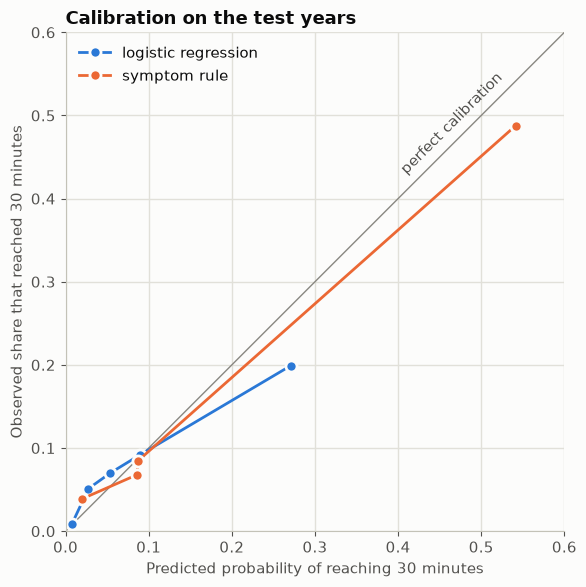

Logistic regression: average prediction 0.090, observed rate 0.084


,predicted,observed
risk group,,
1,0.007,0.008
2,0.028,0.051
3,0.054,0.070
4,0.089,0.092
5,0.271,0.199


In [24]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 0.6], [0, 0.6], color=GREY, linewidth=1)
ax.text(0.40, 0.43, "perfect calibration", color="#52514e", rotation=45)

for method, colour in [("logistic regression", BLUE), ("symptom rule", ORANGE)]:
    observed, predicted = calibration_curve(y2, part2_scores[method], n_bins=5, strategy="quantile")
    ax.plot(predicted, observed, color=colour, linewidth=2, marker="o", markersize=8,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=method)

ax.set_xlim(0, 0.6)
ax.set_ylim(0, 0.6)
ax.set_aspect("equal")
ax.set_xlabel("Predicted probability of reaching 30 minutes")
ax.set_ylabel("Observed share that reached 30 minutes")
ax.set_title("Calibration on the test years", loc="left")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

mean_prediction = part2_scores["logistic regression"].mean()
print(f"Logistic regression: average prediction {mean_prediction:.3f}, observed rate {y2.mean():.3f}")

observed, predicted = calibration_curve(y2, part2_scores["logistic regression"], n_bins=5, strategy="quantile")
pd.DataFrame({"predicted": predicted, "observed": observed}, index=range(1, 6)).rename_axis("risk group").round(3)


### 3.6 Part 1 against Part 2: the target or the timing?

Part 2 changes two things at once: it predicts at minute 5 instead of minute 0, and it targets
30 minutes instead of 10. To separate them, the same model is also fit with the 30-minute target at
minute 0, on all train incidents:

In [25]:
part1["major_30"] = (part1["bucket_min_minutes"] >= 30).astype(int)

rows = []
for version, data, target in [("10+ minutes, at minute 0 (Part 1)", part1, "major"),
                              ("30+ minutes, at minute 0", part1, "major_30"),
                              ("30+ minutes, at minute 5 (Part 2)", part2, "major")]:
    y_test = data.loc[data["period"] == "test", target]
    scores = model_scores(LogisticRegression(max_iter=2000), data, target)
    recall, alerts = recall_with_precision_floor(y_test, scores)
    rows.append({
        "version": version,
        "test incidents": len(y_test),
        "major (test)": int(y_test.sum()),
        "base rate": round(y_test.mean(), 3),
        "PR-AUC": round(average_precision_score(y_test, scores), 3),
        "ROC-AUC": round(roc_auc_score(y_test, scores), 3),
        "recall, 1 in 3 alerts right": round(recall, 2),
        "alerts needed": alerts,
    })
pd.DataFrame(rows)

,version,test incidents,major (test),base rate,PR-AUC,ROC-AUC,"recall, 1 in 3 alerts right",alerts needed
0,"10+ minutes, at minute 0 (Part 1)",8109,625,0.077,0.262,0.766,0.14,244
1,"30+ minutes, at minute 0",8109,156,0.019,0.181,0.822,0.23,104
2,"30+ minutes, at minute 5 (Part 2)",1857,156,0.084,0.299,0.747,0.34,154


**Both changes help, about equally.** On the success measure, moving the target from 10 to
30 minutes at minute 0 takes the share caught from 14% to 23%, and waiting until minute 5 takes it
from 23% to 34%. So of the gain of about 20 points, about 9 come from the target and 11 from the
timing.

With the same 30-minute target, waiting until minute 5 raises PR-AUC from 0.181 to 0.299. Between
Part 1 and Part 2, which have different targets, it only rises from 0.262 to 0.299. ROC-AUC falls at
minute 5 because the many short incidents, which are easy to rank low, are no longer in the
population.

### 3.7 Part 2 conclusion: a better question, not a solved problem

**Elapsed time is an important variable.** In the training years, 1.7% of train incidents reach
30 minutes. Among delays that have lasted 5 minutes, it is 8.1%; at 10 minutes, 26%; at
15 minutes, 48%. The symptom sharpens this: fire, smoke or odour incidents still delaying service
at minute 5 reach 30 minutes 55% of the time.

**The model adds to the symptom.** On the test years, logistic regression scores a PR-AUC of
0.299 (3.6 times the base rate), against 0.213 for the symptom rule, and the difference holds up
(bootstrap interval 0.05 to 0.13). Gradient boosting also beats the rule, with 0.264.

**Against the success criterion, it still falls short, but it gets much closer than Part 1:**

| | Bar | Part 1 (10+ min, at report) | Part 2 (30+ min, at minute 5) |
|---|---|---|---|
| Share of major delays caught, with at least 1 alert in 3 right | 50% | 14% | 34% |
| Alerts this takes (test years) | | 244, about 12 a month | 154, about 7 a month |
| Disruption still to come when a correct alert fires | | at least 10 minutes | at least 25 minutes |

Section 3.6 shows that this gain comes from both the longer target and the later timing. PR-AUC
rises less between the two parts, from 0.262 to 0.299.


**Two high-precision triggers stand out:**

- **Fire, smoke or odour still delaying service at minute 5:** about half reach 30 minutes
  (51% on the test years: 40 of 79 alerts), and they make up a quarter of all 30-minute
  interruptions. The model already puts 78 of these 79 incidents in its riskiest 10%.
- **Any delay still running at minute 15:** about half reach 30 minutes (48% in the training years).

**The probabilities are reasonably calibrated.** The average prediction is 9.0% against 8.4%
observed, and the model is close for low and medium risks, though slightly low (5.4% predicted
against 7.0% observed for the middle group). It overestimates the highest-risk
group (about 27% predicted against 20% observed), so its top scores should be read as "high", not
as exact probabilities.

**Uncertainty:** the test years contain only 156 interruptions of 30 minutes or more, so all of
these figures carry real uncertainty (see the bootstrap intervals).

## 4. Robustness checks

Three checks that the conclusions do not rest on a hidden assumption.

### 4.1 The features we excluded

`metro_emergency`, `traction_power_cut`, `evacuation` and `material_damage` were left out because
they may be set *during or after* the incident. If adding them makes the model much better, that
is a warning sign: the model would be learning from the response to a long incident, which is not
available when the decision has to be made.

In [26]:
part1["has_evacuation"] = (part1["evacuation"] != "Aucune").astype(int)
part2["has_evacuation"] = (part2["evacuation"] != "Aucune").astype(int)

EXCLUDED_FEATURES = ["metro_emergency", "traction_power_cut", "material_damage", "has_evacuation"]

rows = []
for part, data, y_test in [("Part 1 (10+ min at report)", part1, y1),
                                 ("Part 2 (30+ min at minute 5)", part2, y2)]:
    without = model_scores(LogisticRegression(max_iter=2000), data, "major")
    with_excluded = model_scores(LogisticRegression(max_iter=2000), data, "major",
                                 extra_binary_features=EXCLUDED_FEATURES)
    rows.append({
        "part": part,
        "PR-AUC without": round(average_precision_score(y_test, without), 3),
        "PR-AUC with excluded features": round(average_precision_score(y_test, with_excluded), 3),
    })
pd.DataFrame(rows)

,part,PR-AUC without,PR-AUC with excluded features
0,Part 1 (10+ min at report),0.262,0.577
1,Part 2 (30+ min at minute 5),0.299,0.615


**Adding the excluded features roughly doubles PR-AUC** in both parts (0.262 to 0.577, and 0.299
to 0.615). That is the size of the trap: much of the apparent signal in these columns probably
describes the *response* to a long incident (calling the emergency team, cutting traction power to
evacuate, evacuating), which is not available when the decision has to be made.

Some of these may in fact be known early: a traction power cut, for example, can be the cause of
an incident rather than a consequence. **This is a question for STM.** If they record *when* each
flag is set, the ones known by minute 5 can be added safely.

### 4.2 The features whose timing is assumed

Some features are *used*, on the assumption that they are known when the prediction is made, but
the documentation does not say when they are recorded:

- whether a vehicle or run number is recorded (`has_vehicle`, `has_run`);
- the line and the type of location, which include whether the incident affects *several* lines.
  That may only be recorded once a delay has spread, and it is strongly linked to long delays;
- the emergency-brake and door flags.

If a result depended on them, it would rest on that assumption. Each group is removed in turn, then
all three together (logistic regression, test years):

In [27]:
FEATURES_WITH_ASSUMED_TIMING = {
    "has_vehicle, has_run": ["has_vehicle", "has_run"],
    "line, location_type": ["line", "location_type"],
    "emergency_brake, door_involved": ["emergency_brake", "door_involved"],
    "all three groups": ["has_vehicle", "has_run", "line", "location_type", "emergency_brake", "door_involved"],
}

rows = []
for part, data, y_test in [("Part 1 (10+ min at report)", part1, y1),
                                 ("Part 2 (30+ min at minute 5)", part2, y2)]:
    all_features = model_scores(LogisticRegression(max_iter=2000), data, "major")
    row = {"part": part, "PR-AUC, all features": round(average_precision_score(y_test, all_features), 3)}
    for label, columns in FEATURES_WITH_ASSUMED_TIMING.items():
        scores = model_scores(LogisticRegression(max_iter=2000), data, "major",
                              dropped_features=columns)
        row["without " + label] = round(average_precision_score(y_test, scores), 3)
    rows.append(row)
pd.DataFrame(rows)

,part,"PR-AUC, all features","without has_vehicle, has_run","without line, location_type","without emergency_brake, door_involved",without all three groups
0,Part 1 (10+ min at report),0.262,0.235,0.224,0.260,0.188
1,Part 2 (30+ min at minute 5),0.299,0.294,0.296,0.291,0.291


**Part 2 does not depend on these assumptions:** removing any group changes its PR-AUC by less
than 0.01 (0.299 with all features, 0.291 to 0.296 without each group), and removing all three
together still leaves 0.291. **Part 1 does depend on them:** without the line information its PR-AUC
falls from 0.262 to 0.224, and without all three it falls to 0.188. That only makes Part 1 weaker,
so its conclusion does not change.


### 4.3 Target defined by the start and end times instead of the duration category

The targets use STM's duration category (`duration_bucket`). The start and end times give a second
measure of the same delay (`duration_minutes`). The two agree for 98% of train incidents, but that
figure is dominated by the many short incidents. What matters is whether they agree on the
*major* ones:

In [28]:
rows = []
for threshold in [5, 10, 15, 30]:
    by_category = trains["bucket_min_minutes"] >= threshold
    by_times = trains["duration_minutes"] >= threshold
    rows.append({
        "threshold (minutes)": threshold,
        "major by category": int(by_category.sum()),
        "major by times": int(by_times.sum()),
        "by category only": int((by_category & ~by_times).sum()),
        "by times only": int((by_times & ~by_category).sum()),
    })
display(pd.DataFrame(rows))

# The incidents that are 30+ minutes by the times only: what are they?
long_by_times_only = trains[(trains["duration_minutes"] >= 30) & (trains["bucket_min_minutes"] < 30)]
in_lowest_categories = long_by_times_only[long_by_times_only["bucket_min_minutes"] < 5]
print(f"30+ minutes by the times only: {len(long_by_times_only)} incidents")
print(f"  in a category under 5 minutes: {len(in_lowest_categories)}, "
      f"median length by the times {in_lowest_categories['duration_minutes'].median():.0f} minutes")
print("  by year:", long_by_times_only.groupby("year").size().to_dict())


def incident_profile(group):
    """How much a group of incidents looks like a long interruption."""
    return {
        "incidents": len(group),
        "median minutes by the times": group["duration_minutes"].median(),
        "evacuation": (group["evacuation"] != "Aucune").mean(),
        "traction power cut": group["traction_power_cut"].mean(),
        "emergency team": group["metro_emergency"].mean(),
        "run number recorded": group["has_run"].mean(),
        "at a station": (group["location_type"] == "station").mean(),
    }


display(pd.DataFrame({
    "30+ by category": incident_profile(trains[trains["bucket_min_minutes"] >= 30]),
    "30+ by times, category under 5": incident_profile(in_lowest_categories),
    "all train incidents": incident_profile(trains),
}).round(3))

# Why we read the category as the delay to service: it ignores how long station incidents last.
station_incidents = incidents[incidents["incident_type"] == "S"]
print(f"Station incidents: {len(station_incidents):,}, "
      f"{(station_incidents['bucket_min_minutes'] == 0).mean():.0%} in the lowest category, "
      f"median length by the times {station_incidents['duration_minutes'].median():.0f} minutes")

,threshold (minutes),major by category,major by times,by category only,by times only
0,5,6413,6687,17,291
1,10,2036,2407,4,375
2,15,1103,1371,4,272
3,30,524,664,1,141


30+ minutes by the times only: 141 incidents
  in a category under 5 minutes: 102, median length by the times 59 minutes
  by year: {2019: 8, 2020: 12, 2021: 16, 2022: 19, 2023: 29, 2024: 37, 2025: 20}


,30+ by category,"30+ by times, category under 5",all train incidents
incidents,524.000,102.000,29166.000
median minutes by the times,49.000,59.000,2.000
evacuation,0.781,0.010,0.047
traction power cut,0.876,0.088,0.242
emergency team,0.406,0.029,0.016
run number recorded,0.956,0.333,0.813
at a station,0.672,0.863,0.858


Station incidents: 16,390, 100% in the lowest category, median length by the times 41 minutes


If the conclusions depended on which measure defines a major interruption, they would rest on an
undocumented choice. The same models are fit with the target defined by the times. In the last
version, the times also decide which delays count as interruptions (5 minutes or more):

In [29]:
part1["major_by_times"] = (part1["duration_minutes"] >= 10).astype(int)
part2["major_by_times"] = (part2["duration_minutes"] >= 30).astype(int)
part2_by_times = trains[trains["duration_minutes"] >= 5].copy()
part2_by_times["major_by_times"] = (part2_by_times["duration_minutes"] >= 30).astype(int)

VERSIONS = [
    ("Part 1, as above", part1, "major"),
    ("Part 1, target by times", part1, "major_by_times"),
    ("Part 2, as above", part2, "major"),
    ("Part 2, target by times (same delays)", part2, "major_by_times"),
    ("Part 2, delays and target by times", part2_by_times, "major_by_times"),
]

rows = []
for version, data, target in VERSIONS:
    train_data = data[data["period"] == "train"]
    test_data = data[data["period"] == "test"]
    y_test = test_data[target]
    rule = symptom_rule_scores(train_data, test_data, target)
    model = model_scores(LogisticRegression(max_iter=2000), data, target)
    recall, alerts = recall_with_precision_floor(y_test, model)
    rows.append({
        "version": version,
        "test incidents": len(y_test),
        "major (test)": int(y_test.sum()),
        "base rate": round(y_test.mean(), 3),
        "PR-AUC, symptom rule": round(average_precision_score(y_test, rule), 3),
        "PR-AUC, logistic regression": round(average_precision_score(y_test, model), 3),
        "recall, 1 in 3 alerts right": round(recall, 2),
        "alerts needed": alerts,
    })
pd.DataFrame(rows)

,version,test incidents,major (test),base rate,"PR-AUC, symptom rule","PR-AUC, logistic regression","recall, 1 in 3 alerts right",alerts needed
0,"Part 1, as above",8109,625,0.077,0.118,0.262,0.14,244
1,"Part 1, target by times",8109,756,0.093,0.132,0.254,0.13,286
2,"Part 2, as above",1857,156,0.084,0.213,0.299,0.34,154
3,"Part 2, target by times (same delays)",1857,165,0.089,0.212,0.301,0.38,185
4,"Part 2, delays and target by times",1964,213,0.108,0.234,0.360,0.48,303


In [30]:
# In the last version, which incidents does the model catch?
scores = model_scores(LogisticRegression(max_iter=2000), part2_by_times, "major_by_times")
test_data = part2_by_times[part2_by_times["period"] == "test"].copy()
test_data["score"] = scores
recall, alerts = recall_with_precision_floor(test_data["major_by_times"], scores)
caught = test_data.nlargest(alerts, "score")
caught = caught[caught["major_by_times"] == 1]
under_5_by_category = caught[caught["bucket_min_minutes"] < 5]
print(f"Major incidents caught with {alerts} alerts: {len(caught)}")
print(f"  of which the duration category puts under 5 minutes: {len(under_5_by_category)}")

Major incidents caught with 303 alerts: 103
  of which the duration category puts under 5 minutes: 36


**The two measures disagree on the major incidents, almost always in the same direction.** The
times give more major incidents than the category at every threshold (18% more at 10 minutes, 27%
more at 30), and almost never fewer. Of the 141 incidents that last 30 minutes or more by the
times only, 102 are in a category under 5 minutes, even though their times span 59 minutes at the
median. They do not look like long interruptions: an evacuation in 1% of them against 78% of the
30-minute incidents by category, a traction power cut in 9% against 88%, and the emergency team in
3% against 41%. These disagreements are also
rising, from 8 in 2019 to 37 in 2024.

**The conclusions hold when only the target changes.** Part 1 scores a PR-AUC of 0.254 instead of
0.262 (13% caught instead of 14%). Part 2 scores 0.301 instead of 0.299 (38% caught instead of
34%), still short of the 50% bar.

**When the times also decide which delays count, Part 2 comes close to the bar (48%)**, but largely
because of these incidents: 36 of the 103 major incidents it catches are ones the category puts
under 5 minutes. If the category is right, they are not service
interruptions, and most of the gain is not real. If the times are right, the gain is real, and the
model is close to the bar.

**So which measure defines a major interruption is a judgment call, and the most consequential
undocumented one in this analysis.** We keep the category, but that rests on an inference. The
documentation defines the train start and end times as the delay to customers and does not mention
the category at all, so on paper the times have the stronger claim. We read the category as the
delay to service for two reasons: every station incident is in its lowest category, whatever its
length (median 41 minutes), and the incidents it puts under 5 minutes but the times put at 30 or more
show almost none of the evacuations, power cuts or emergency calls that usually come with a long
interruption. **This is the first question for STM:** which measure defines an interruption? STM should
also document `Incident en minutes`.

## 5. Reliability trends: service volume and classification

STM is unsure whether the trends in the incident data reflect reliability, **service volume**,
reporting practices or classification. More service means more trains running, and so more
chances for incidents. Dividing incidents by the kilometres of service planned separates the
volume effect from the rest (sections 5.1 to 5.3). Sections 5.4 and 5.5 check classification.

How the two files are combined:

- **Planned km** is per line per day, from January 2019 to **September 2023 only**. Incidents
  after that date have nothing to compare with.
- **Only train incidents on a single line** can be matched to a line's kilometres. Incidents on
  several lines, or not on a line, are left out (counted below).
- **Interruptions** use STM's own definition, delays of 5 minutes or more, with 30 minutes or more
  shown separately.
- The km file's date is assumed to be a service day, like the incidents' year and month. This only
  matters for the few incidents just after midnight at the end of a month.
- Planned km is *planned*, not actually run, so the rates are approximate.
- **The km unit is not documented.** It is very likely car-km, where a 9-car train counts nine times
  its distance, rather than train-km. Section 5.2 checks this, because it affects comparisons between
  lines with different train lengths, though not the trend within a line.

In [31]:
planned_km = clean_planned_km()
last_km_date = planned_km["date"].max()
print(f"Planned km: {planned_km['date'].min().date()} to {last_km_date.date()}")

# Train incidents in the period covered by planned km, on a single line.
in_km_period = trains["service_date"] <= last_km_date
on_one_line = trains["line"].isin(planned_km["line"].unique())
rated = trains[in_km_period & on_one_line].copy()
left_out = trains[in_km_period & ~on_one_line]
print(f"{len(rated):,} train incidents on a single line; {len(left_out)} on several lines or none left out")

rated["interruption_5_min"] = (rated["bucket_min_minutes"] >= 5).astype(int)
rated["interruption_30_min"] = (rated["bucket_min_minutes"] >= 30).astype(int)


def rates_per_km(incidents, km, group_column):
    """Interruptions, planned km and interruptions per million km, for each group."""
    table = incidents.groupby(group_column)[["interruption_5_min", "interruption_30_min"]].sum()
    table["planned_km_millions"] = km.groupby(group_column)["planned_km"].sum() / 1_000_000
    table["5+ min per million km"] = table["interruption_5_min"] / table["planned_km_millions"]
    table["30+ min per million km"] = table["interruption_30_min"] / table["planned_km_millions"]
    return table.round(2)

Planned km: 2019-01-01 to 2023-09-30
19,611 train incidents on a single line; 258 on several lines or none left out


### 5.1 Over time

The km data stops at the end of September 2023, and incidents are seasonal (winter has the most).
To compare years fairly, every year below covers **January to September only**.

In [32]:
by_year = rates_per_km(rated[rated["month"] <= 9],
                       planned_km[planned_km["month"] <= 9],
                       "year")
# Planned km stops in September 2023, so the later years can be counted but not turned into rates.
later_years = trains[(trains["year"] >= 2024) & trains["line"].isin(planned_km["line"].unique())
                     & (trains["month"] <= 9) & (trains["bucket_min_minutes"] >= 5)]
print("Interruptions of 5+ minutes, January to September:", later_years.groupby("year").size().to_dict())

by_year


Interruptions of 5+ minutes, January to September: {2024: 824, 2025: 701}


,interruption_5_min,interruption_30_min,planned_km_millions,5+ min per million km,30+ min per million km
year,,,,,
2019,650,40,66.87,9.72,0.60
2020,635,49,66.66,9.53,0.74
2021,601,48,62.84,9.56,0.76
2022,650,57,63.02,10.31,0.90
2023,799,46,61.56,12.98,0.75


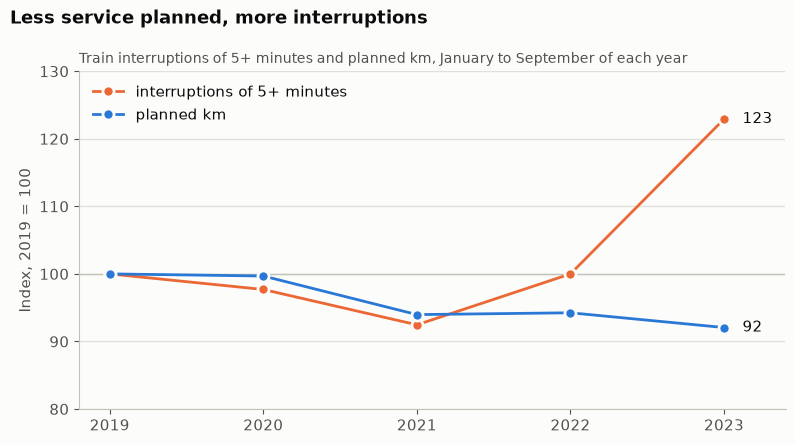

In [33]:
# Both measures as an index (2019 = 100), so they can share one axis.
index = pd.DataFrame({
    "interruptions of 5+ minutes": by_year["interruption_5_min"],
    "planned km": by_year["planned_km_millions"],
})
index = index / index.loc[2019] * 100

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.axhline(100, color="#c3c2b7", linewidth=1)
for column, colour in [("interruptions of 5+ minutes", ORANGE), ("planned km", BLUE)]:
    ax.plot(index.index, index[column], color=colour, linewidth=2, marker="o", markersize=8,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=column)
    last_value = index.loc[2023, column]
    ax.text(2023.12, last_value, f"{last_value:.0f}", va="center", color="#0b0b0b")

ax.set_xticks(index.index)
ax.set_xlim(2018.8, 2023.4)
ax.set_ylim(80, 130)
ax.set_ylabel("Index, 2019 = 100")
ax.grid(axis="x", visible=False)
fig.suptitle("Less service planned, more interruptions", x=0.01, ha="left", fontweight="bold")
ax.set_title("Train interruptions of 5+ minutes and planned km, January to September of each year",
             loc="left", fontsize=10, color="#52514e", fontweight="normal")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

### 5.2 By line

The whole period covered by planned km (January 2019 to September 2023), sorted by the rate of
interruptions per million km:

In [34]:
by_line = rates_per_km(rated, planned_km, "line")
by_line.sort_values("5+ min per million km", ascending=False)

,interruption_5_min,interruption_30_min,planned_km_millions,5+ min per million km,30+ min per million km
line,,,,,
Ligne verte,1894,145,147.76,12.82,0.98
Ligne bleue,461,35,38.23,12.06,0.92
Ligne jaune,213,14,23.31,9.14,0.60
Ligne orange,1635,125,198.81,8.22,0.63


**What does a km mean here?** The documentation gives no unit. The next cell checks whether the
figures can be train-km, then repeats the comparison with the orange line per train-km. This needs
figures that are not in the data, and are assumptions here: a network length of 69.2 km, about
19.5 hours of service a day, and train lengths of 6 cars on the blue line and 9 on the green and
orange lines. Sources conflict for the yellow line, so both lengths are shown.

In [35]:
# Could these be train-km? If so, how often would a train run on a normal weekday?
NETWORK_LENGTH_KM = 69.2
SERVICE_MINUTES_PER_DAY = 19.5 * 60
ORANGE_CARS_PER_TRAIN = 9

one_weekday_km = planned_km.loc[planned_km["date"] == "2019-03-13", "planned_km"].sum()
trains_per_direction = one_weekday_km / NETWORK_LENGTH_KM / 2
minutes_between_trains = SERVICE_MINUTES_PER_DAY / trains_per_direction
print(f"Planned km on Wednesday 2019-03-13: {one_weekday_km:,.0f}")
print(f"If train-km: a train every {minutes_between_trains * 60:.0f} seconds in each direction")
print(f"If car-km on 9-car trains: a train every {minutes_between_trains * 9:.1f} minutes")


def ratio_to_orange(line, count_column, cars_per_train):
    """The line's rate per train-km divided by orange's, with a 95% interval (Poisson counts).

    With 9 cars for every line, the train lengths cancel out and this is the ratio per car-km.
    """
    count = by_line.loc[line, count_column]
    orange_count = by_line.loc["Ligne orange", count_column]
    rate = count / (by_line.loc[line, "planned_km_millions"] / cars_per_train)
    orange_rate = orange_count / (by_line.loc["Ligne orange", "planned_km_millions"] / ORANGE_CARS_PER_TRAIN)
    ratio = rate / orange_rate
    margin = 1.96 * np.sqrt(1 / count + 1 / orange_count)
    return f"{ratio:.2f} ({ratio * np.exp(-margin):.2f} to {ratio * np.exp(margin):.2f})"


rows = []
for label, line, cars in [("green, 9 cars", "Ligne verte", 9),
                          ("blue, 6 cars", "Ligne bleue", 6),
                          ("yellow, if 6 cars", "Ligne jaune", 6),
                          ("yellow, if 9 cars", "Ligne jaune", 9)]:
    rows.append({
        "against orange": label,
        "5+ min, per car-km": ratio_to_orange(line, "interruption_5_min", 9),
        "5+ min, per train-km": ratio_to_orange(line, "interruption_5_min", cars),
        "30+ min, per car-km": ratio_to_orange(line, "interruption_30_min", 9),
        "30+ min, per train-km": ratio_to_orange(line, "interruption_30_min", cars),
    })
pd.DataFrame(rows)

Planned km on Wednesday 2019-03-13: 278,559
If train-km: a train every 35 seconds in each direction
If car-km on 9-car trains: a train every 5.2 minutes


,against orange,"5+ min, per car-km","5+ min, per train-km","30+ min, per car-km","30+ min, per train-km"
0,"green, 9 cars",1.56 (1.46 to 1.67),1.56 (1.46 to 1.67),1.56 (1.23 to 1.98),1.56 (1.23 to 1.98)
1,"blue, 6 cars",1.47 (1.32 to 1.63),0.98 (0.88 to 1.08),1.46 (1.00 to 2.12),0.97 (0.67 to 1.41)
2,"yellow, if 6 cars",1.11 (0.96 to 1.28),0.74 (0.64 to 0.85),0.96 (0.55 to 1.66),0.64 (0.37 to 1.11)
3,"yellow, if 9 cars",1.11 (0.96 to 1.28),1.11 (0.96 to 1.28),0.96 (0.55 to 1.66),0.96 (0.55 to 1.66)


### 5.3 What this shows

**Service volume does not explain the rise in interruptions.** From 2019 to 2022, interruptions
moved with the amount of service: both dipped in 2021, and the rate stayed between 9.5 and 10.3
interruptions per million km. In 2023 they split apart: planned km was 8% below 2019, but
interruptions of 5 minutes or more were 23% above, and the rate jumped to 13.0 per million km.
The higher level continued in 2024 (824 interruptions from January to September, against 650 in
2019) and eased in 2025 (701), but planned km is not available for those years, so they cannot
be turned into rates. The 2025 drop shows no sign of being missing data (section 1.2).

Interruptions of 30 minutes or more rose from 0.60 to 0.90 per million km between 2019 and 2022,
then fell back to 0.75 in 2023. With only 40 to 57 a year, that is too few to tell a real trend
from year-to-year variation.

**So the 2023 rise reflects either a real drop in reliability or a change in how incidents are
recorded or classified.** This data cannot tell which. STM would need to check whether its
recording practices changed in 2023. Sections 5.4 and 5.5 look at two of them: the symptom and
the secondary cause.

**By line, raw counts mislead, and the km unit matters.** The green and orange lines have similar numbers of interruptions
(1,894 and 1,635), but the orange line runs about a third more service. Per million km, the green
(12.8) and blue (12.1) lines have about 50% more interruptions than the orange line (8.2), with
the yellow line (9.1) close to the orange. The same pattern holds for interruptions of 30 minutes
or more.

But the km are very likely car-km: as train-km, they would mean a train about every 35 seconds in
each direction. That makes lines with shorter trains look worse. Per train-km, the green line stays
about 50% above the orange line (1.56 times, interval 1.46 to 1.67), while the blue line is level
with it (0.98 times, interval 0.88 to 1.08). So the green line stands out on both measures, and the
blue line only per car-km. Neither measure is simply right: train faults may scale with cars, while a
delay to a line may scale more with trains. The trend over time is not affected, as long as train
lengths stayed the same. Any comparison of lines, for example to prioritise investment, should use
rates, not counts, and state the unit.

**Limits:** the km figures are planned, not actually run; their unit and the train lengths are
assumptions; they stop in September 2023; 258
incidents on several lines or none are left out (1.3%); and the yellow line has few severe
interruptions (14), so its 30-minute rate is uncertain.

### 5.4 Is it classification? How symptoms are recorded over time

STM is also unsure whether trends reflect **classification consistency**. The symptom is the one
classification that every train incident has, and a key model feature, so this section checks
whether it is recorded the same way every year. All train incidents are used here, on every line
and up to September 2025 (missing symptoms are `Inconnu`).

In [36]:
SHIFTING_SYMPTOMS = ["Exploitation stations", "Exploitation trains"]

share_by_year = pd.crosstab(trains["symptom"], trains["year"], normalize="columns") * 100
print("Share of train incidents (%), by year (2025: January to September):")
display(share_by_year.loc[SHIFTING_SYMPTOMS].round(1))

print("Train incidents with no symptom recorded:")
display(trains[trains["symptom"] == "Inconnu"].groupby("year").size())

stations = incidents[incidents["incident_type"] == "S"]
print("Station incidents with no symptom recorded:")
display(stations[stations["symptom"].isna()].groupby("year").size())

Share of train incidents (%), by year (2025: January to September):


year,2019,2020,2021,2022,2023,2024,2025
symptom,,,,,,,
Exploitation stations,0.8,1.0,2.2,3.1,3.4,4.7,8.8
Exploitation trains,12.3,9.3,7.3,6.1,4.9,4.0,5.4


Train incidents with no symptom recorded:


year
2019     2
2020     2
2021     7
2022    17
2023    21
2024    22
2025    12
dtype: int64

Station incidents with no symptom recorded:


year
2019     9
2020     2
2021     7
2022    45
2023    73
2024    78
2025    80
dtype: int64

In [37]:
reached_5_min = trains["bucket_min_minutes"] >= 5
print("Share of train incidents that reached 5 minutes, by symptom (all years):")
display(reached_5_min.groupby(trains["symptom"]).mean().round(3).sort_values())

# Where did the 2023 rise come from? Interruptions of 5+ minutes, January to September.
interruptions = trains[(trains["month"] <= 9) & reached_5_min]
by_symptom = pd.crosstab(interruptions["symptom"], interruptions["year"])
by_symptom["change 2022 to 2023"] = by_symptom[2023] - by_symptom[2022]
by_symptom.sort_values("change 2022 to 2023", ascending=False)

Share of train incidents that reached 5 minutes, by symptom (all years):


symptom
Exploitation stations                 0.011
Exploitation trains                   0.105
Inconnu                               0.145
Clientèle                             0.194
Feu, fumée, odeur, produit, etc...    0.204
Matériel roulant                      0.264
Équipements fixes                     0.334
Divers                                0.340
Name: bucket_min_minutes, dtype: float64

year,2019,2020,2021,2022,2023,2024,2025,change 2022 to 2023
symptom,,,,,,,,
Clientèle,211,221,230,269,328,332,337,59
Matériel roulant,294,256,163,190,247,244,224,57
Équipements fixes,90,107,168,142,188,208,109,46
Exploitation trains,37,28,21,10,17,28,32,7
Inconnu,0,2,1,0,3,1,1,3
Exploitation stations,0,1,1,1,1,2,1,0
Divers,9,3,9,4,0,0,1,-4
"Feu, fumée, odeur, produit, etc...",20,25,27,38,29,38,31,-9


**The symptom categories have changed over time.** `Exploitation stations` (operations in
stations) is not in the documentation's list of symptoms, yet it is used for a growing share of
*train* incidents: 0.8% in 2019, 4.7% in 2024 and 8.8% in 2025. Over the same years,
`Exploitation trains` fell from 12.3% to about 5%. The change is gradual, which points to a change
in how incidents are classified rather than in what happens. Missing symptoms also rise, from 2 a
year to about 20 for train incidents, and from 9 to about 80 for station incidents.

**This does not explain the 2023 rise in interruptions.** Both categories rarely lead to a delay:
1% of `Exploitation stations` train incidents and 11% of `Exploitation trains` ones reached
5 minutes, against 19% to 33% for the four main symptoms. From January to September 2022 to 2023, the rise is
spread across the main symptoms instead: customers (269 to 328), rolling stock (190 to 247) and
fixed equipment (142 to 188).

**What it means:**

- **For the models, little.** The shifting categories are low-risk whichever way an incident is
  classified, and few of them reach 5 minutes, so they barely enter Part 2. But the symptom does not
  mean exactly the same thing in the training and test years.
- **For measuring reliability, a warning.** A trend in a single symptom (for example fewer
  "train operations" incidents) may reflect classification, not reliability. STM should keep its
  categories stable, or document when they change.
- It does not rule out other recording changes in 2023, for example in how durations are measured.

### 5.5 A surge in one cause inside the test years

Causes cannot be model features (section 1.3), but they show how incidents were classified
afterwards. One secondary cause, `Service de la voie`, surges in 2024:

In [38]:
track_service = trains[trains["secondary_cause"] == "Service de la voie"]
print("Train incidents with this secondary cause, by month (2025 stops in September):")
display(track_service[track_service["year"] >= 2022]
        .groupby(["year", "month"]).size().unstack("month", fill_value=0))

aug_sep_2024 = trains[(trains["year"] == 2024) & trains["month"].isin([8, 9])]
surge = aug_sep_2024[aug_sep_2024["secondary_cause"] == "Service de la voie"]
print(f"August and September 2024: {len(surge)} of {len(aug_sep_2024)} train incidents "
      f"({len(surge) / len(aug_sep_2024):.0%}), {(surge['bucket_min_minutes'] < 5).sum()} of them under 5 minutes")
print("Primary cause, all years:", track_service["primary_cause"].value_counts().to_dict())

print("Symptom given to incidents with this cause, share by year:")
symptom_by_year = pd.crosstab(track_service["year"], track_service["symptom"], normalize="index")
display(symptom_by_year[["Équipements fixes", "Matériel roulant"]].round(2))

rolling_stock_2024 = trains[(trains["year"] == 2024) & (trains["symptom"] == "Matériel roulant")]
print("Rolling-stock symptom, 2024, by month:", rolling_stock_2024.groupby("month").size().to_dict())

Train incidents with this secondary cause, by month (2025 stops in September):


month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2022,15,7,12,13,15,14,20,24,41,17,13,9
2023,16,12,15,9,14,23,56,63,54,54,14,7
2024,11,5,11,6,65,33,62,178,245,135,57,24
2025,17,26,20,18,11,11,12,10,5,0,0,0


August and September 2024: 423 of 1035 train incidents (41%), 337 of them under 5 minutes
Primary cause, all years: {'Équipements fixes': 1966}
Symptom given to incidents with this cause, share by year:


symptom,Équipements fixes,Matériel roulant
year,,
2019,0.82,0.04
2020,0.70,0.11
2021,0.79,0.07
2022,0.70,0.18
2023,0.41,0.50
2024,0.24,0.72
2025,0.48,0.38


Rolling-stock symptom, 2024, by month: {1: 102, 2: 80, 3: 56, 4: 75, 5: 104, 6: 101, 7: 139, 8: 236, 9: 242, 10: 164, 11: 77, 12: 88}


In [39]:
# Does this cause explain the 2023 rise? The rate per km with and without these incidents.
without_cause = rated[(rated["month"] <= 9) & (rated["secondary_cause"] != "Service de la voie")]
rate_without = rates_per_km(without_cause, planned_km[planned_km["month"] <= 9], "year")
display(pd.DataFrame({"5+ min per million km": by_year["5+ min per million km"],
                      "without this cause": rate_without["5+ min per million km"]}))

# Do the test results depend on these two months?
for part, test_rows, y_test, scores in [("Part 1", part1_test, y1, part1_scores["logistic regression"]),
                                        ("Part 2", part2_test, y2, part2_scores["logistic regression"])]:
    keep = ~((test_rows["year"] == 2024) & test_rows["month"].isin([8, 9])).to_numpy()
    print(f"{part}: PR-AUC {average_precision_score(y_test, scores):.3f}, "
          f"without August and September 2024 {average_precision_score(y_test[keep], scores[keep]):.3f}")

,5+ min per million km,without this cause
year,,
2019,9.72,9.26
2020,9.53,8.87
2021,9.56,8.10
2022,10.31,9.11
2023,12.98,11.63


Part 1: PR-AUC 0.262, without August and September 2024 0.272
Part 2: PR-AUC 0.299, without August and September 2024 0.312


**One cause surges inside the test years.** `Service de la voie` accounts for mostly 5 to 65 train
incidents a month. In August and September 2024 it accounts for 423, or 41% of train incidents in
those months, and most of them (337) stay under 5 minutes.

**The symptom given to this cause has also changed.** Every incident with this cause has fixed
equipment as its primary cause. In 2019, 82% of them also had a fixed-equipment symptom and 4% a
rolling-stock one. In 2024, it was 24% and 72%. As a result, rolling-stock symptoms more than double
in those two months (236 and 242, against 56 to 104 a month in the first half of 2024). This data
cannot say whether that reflects real events or a change in how symptoms are assigned, so it is a
question for STM.

**What it means:**

- **For measuring reliability:** another reason not to read a trend in one symptom at face value.
- **For the 2023 rise:** it does not explain it. Without this cause, the rate per km still jumps
  from 9.1 to 11.6.
- **For the models:** the test results do not hinge on these two months. Without them, PR-AUC would
  be 0.272 instead of 0.262 in Part 1, and 0.312 instead of 0.299 in Part 2.

Conclusions and recommendations are in the [README](README.md).
